# 02 - Exploratory data analysis (Week 2)

**Input:** `data/processed/runners_merged.parquet`, written by `clean_data.py`.
**Output:** the figures in `reports/figures/` and the findings list below.

Run the cells top to bottom: **Kernel > Restart Kernel and Run All Cells**. Every chart compares the two sources: **Kaggle 2017-20** (blue) and **HKJC 2025-26** (orange). The HKJC data also includes the first 98 races of 2026/27 (Sep-Oct 2026).

Each section ends with a small table. Use those numbers for the findings below.





In [ ]:
## Findings

1. **Coverage.** 3,179 valid races and 38,942 starters. Kaggle: 2,216 races (2017/18-2019/20; no data after 16 May 2018 or after 21 Jun 2020). HKJC: 963 races (all of 2025/26 plus 98 races of 2026/27).
2. **The baseline to beat.** Market per-race log loss is **1.987** (Kaggle) and **2.035** (HKJC), against 2.486 / 2.516 for guessing 1/field size. The favourite wins 31.3% / 29.2% of races. The market is close to well calibrated in both periods.
3. **Kaggle odds are capped at 99** before 13 Mar 2019 (8.7% of 2017/18 and 5.4% of 2018/19 runners; column `odds_capped`). Read "99" as "99 or longer".
4. **HKJC blanks are not random.** 28.5% of 2025/26 starters have no country/age/rating, against 2.9% in 2026/27. They won 4.0% of the time vs 9.7% (median odds 22 vs 14). They are mostly horses that left Hong Kong racing before the scrape, so a blank carries future information: never use it as a feature, and don't drop these rows.
5. **The two periods look alike.** Median odds 15 vs 16; median field size 12, age 5, distance 1,400 m in both. Differences: HKJC fields are full (14 runners) more often (37.1% vs 28.7% of races), and Kaggle has more 3-year-olds (11.1% vs 2.9%), though HKJC ages are missing for the horses in point 4.
6. **Draw bias at Happy Valley, steady across both periods.** Draws 1-2 win 13.9-14.7% of the time vs 3.9-5.2% for draws 10+ (no-bias rate about 8.5%). Weaker at Sha Tin: 8.9-11.8% vs 6.0-7.0%.
7. **Weight.** The win rate rises with carried weight (Kaggle 5.7% to 9.7%, HKJC 6.6% to 8.7%): better horses carry more and the handicap does not fully even them out. HKJC rating relative to the race shows only a weak, noisy rise (7.5-10.3%).
8. **Winning times agree** between sources within about 0.6 s at every common distance except 2400 m (only 3 HKJC races), e.g. 1200 m turf 69.34 vs 69.74 s, so the times were read correctly.
9. **People carry over.** 27 of 47 HKJC jockeys and 22 of 45 trainers also appear in 2017-20, covering 68% / 67% of 2025-26 rides. Some are new (e.g. J Orman, 523 rides), so history features won't exist for every ride.

**For modelling (Week 3):** model on `race_valid & started`, target `is_winner`, beat the market log loss above, split by date. Useful shared features: draw (with track and distance), carried weight, field size, distance, surface, jockey/trainer history. `official_rating` is HKJC-only.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# find the project folder (the one with clean_data.py), whether Jupyter starts in it or in notebooks/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "clean_data.py").exists())
DATA = ROOT / "data/processed/runners_merged.parquet"
FIG = ROOT / "reports/figures"; FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(DATA)
m = df[df.race_valid & df.started].copy()        # modelling rows: valid races, horses that started
print(f"all rows: {len(df):,}   modelling rows: {len(m):,}   races: {m.race_id.nunique():,}")

# --- chart style: one colour per source, thin marks, quiet grid -------------------------------
SRC = {"kaggle": ("Kaggle 2017-20", "#2a78d6"), "hkjc": ("HKJC 2025-26", "#eb6834")}
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "lines.markersize": 6, "legend.frameon": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "figure.dpi": 110,
})
def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"{name}.png", dpi=150); plt.show()

all rows: 39,210   modelling rows: 38,942   races: 3,179


## 1. Coverage - races per month

Look for gaps. Kaggle 2017/18 stops on 16 May 2018 and 2019/20 on 21 Jun 2020. There is no racing in August (summer break).

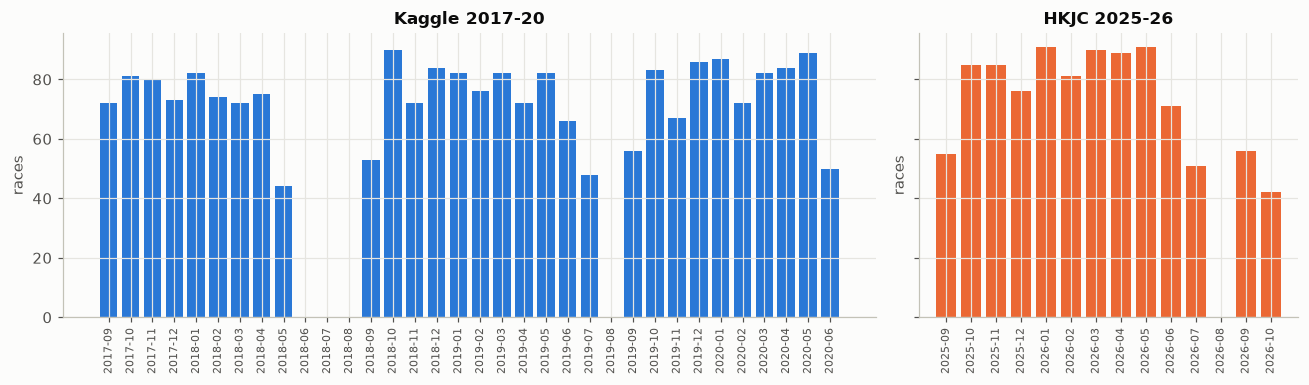

meetings  races
source season                  
hkjc   2025/26        88    865
       2026/27        10     98
kaggle 2017/18        72    653
       2018/19        88    807
       2019/20        80    756

In [2]:
races = m.drop_duplicates("race_id")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True,
                         gridspec_kw={"width_ratios": [3, 1.4]})
for ax, src in zip(axes, ["kaggle", "hkjc"]):
    label, colour = SRC[src]
    s = races[races.source == src].groupby(races.race_date.dt.to_period("M")).size()
    full = pd.period_range(s.index.min(), s.index.max(), freq="M")
    s = s.reindex(full, fill_value=0)
    ax.bar(s.index.astype(str), s.values, color=colour, width=0.8)
    ax.set_title(label); ax.set_ylabel("races")
    ax.tick_params(axis="x", rotation=90, labelsize=7)
save(fig, "01_coverage_races_per_month")
races.groupby(["source", "season"]).agg(meetings=("race_date", "nunique"), races=("race_id", "size"))

## 2. Missing values (modelling rows)

Only columns filled in **both** sources can be features on the merged data. Columns filled in one source only can still be used in a source-specific model, e.g. `official_rating` for HKJC.

The second table checks whether HKJC's missing country / age / rating is random. It isn't: the gaps are mostly 2025/26 horses that had left Hong Kong racing by the time the scraper ran, and they win far less often. So the gap carries **future** information: never use `profile_missing` (or missingness itself) as a feature, and don't drop these rows.

In [3]:
cols = ["draw", "carried_weight_lb", "horse_country", "horse_age", "official_rating", "race_class",
        "win_odds", "market_prob", "finish_time_s", "running_positions", "kaggle_fg_figure"]
miss = (m.groupby("source")[cols].apply(lambda g: g.isna().mean()).T * 100).round(1)
miss.columns = [SRC[c][0] for c in miss.columns]
miss.style.format("{:.1f}%").background_gradient(cmap="Blues", vmin=0, vmax=100)

,HKJC 2025-26,Kaggle 2017-20
draw,0.0%,0.0%
carried_weight_lb,0.0%,0.0%
horse_country,25.9%,0.0%
horse_age,25.9%,0.0%
official_rating,27.5%,100.0%
race_class,3.6%,100.0%
win_odds,0.0%,0.0%
market_prob,0.0%,0.0%
finish_time_s,100.0%,0.0%
running_positions,0.0%,100.0%


In [4]:
h = m[m.source == "hkjc"]
(h.groupby(["season", "profile_missing"])
   .agg(runners=("is_winner", "size"), win_rate=("is_winner", "mean"), median_odds=("win_odds", "median"))
   .round(3))

runners  win_rate  median_odds
season  profile_missing                                
2025/26 False               7719     0.097         14.0
        True                3078      0.04         22.0
2026/27 False               1185     0.083         15.0
        True                  36       0.0         23.0

## 3. Distributions - is 2025-26 like 2017-20?

The step lines show the share of runners in each bin. Big differences mean **drift**, so a model trained on 2017-20 may not transfer.

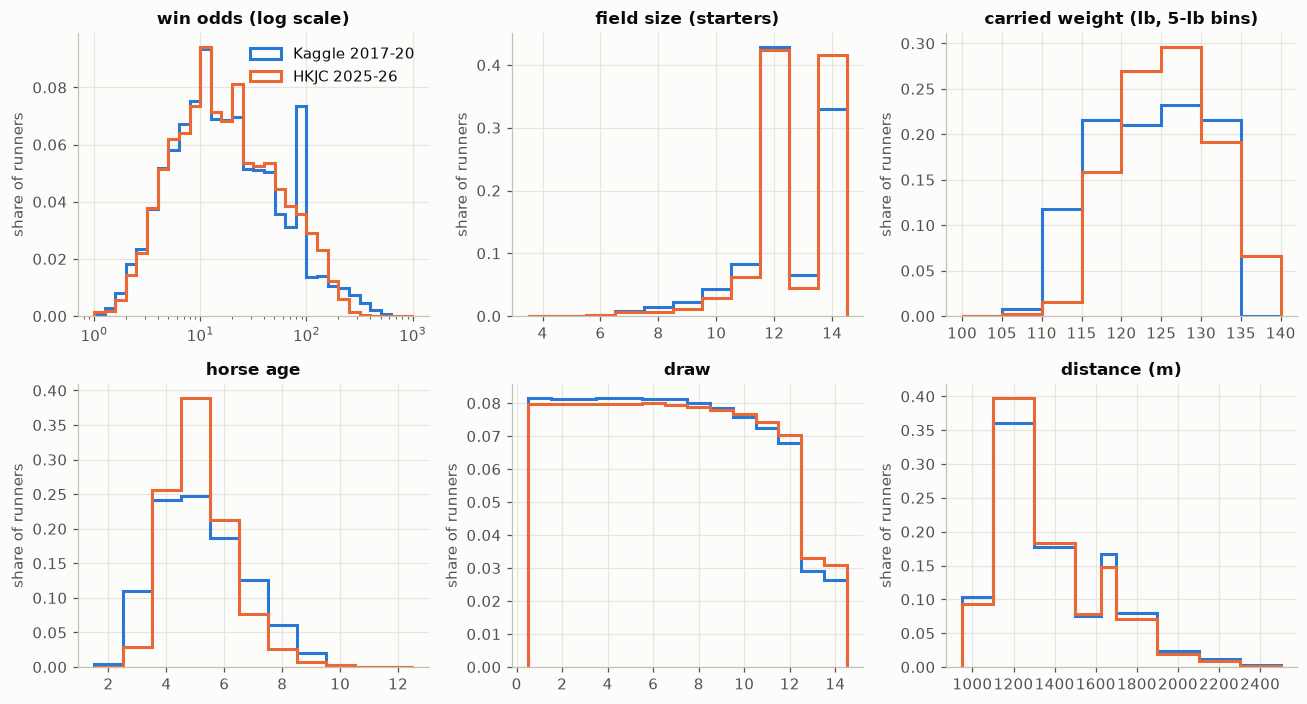

,win_odds,field_size,carried_weight_lb,horse_age,distance_m
source,,,,,
hkjc,16.0,12.0,125.0,5.0,1400.0
kaggle,15.0,12.0,123.5,5.0,1400.0


,"full fields (14 starters), % of races","3-year-olds, % of runners with an age"
source,,
hkjc,37.1,2.9
kaggle,28.7,11.1


In [5]:
specs = [("win_odds", np.geomspace(1, 1000, 31), True, "win odds (log scale)"),
         ("field_size", np.arange(3.5, 15.5, 1), False, "field size (starters)"),
         ("carried_weight_lb", np.arange(100, 141, 5), False, "carried weight (lb, 5-lb bins)"),
         ("horse_age", np.arange(1.5, 13.5, 1), False, "horse age"),
         ("draw", np.arange(0.5, 15.5, 1), False, "draw"),
         ("distance_m", [950, 1100, 1300, 1500, 1625, 1700, 1900, 2100, 2300, 2500], False, "distance (m)")]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, (col, bins, logx, title) in zip(axes.flat, specs):
    for src in ["kaggle", "hkjc"]:
        x = m.loc[m.source == src, col].dropna().astype(float)
        if len(x):
            w = np.ones(len(x)) / len(x)
            ax.hist(x, bins=bins, weights=w, histtype="step", linewidth=2, color=SRC[src][1],
                    label=SRC[src][0])
    if logx: ax.set_xscale("log")
    else: ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_title(title); ax.set_ylabel("share of runners")
axes.flat[0].legend()
save(fig, "02_distributions")
display(m.groupby("source")[["win_odds", "field_size", "carried_weight_lb", "horse_age", "distance_m"]].median())
r = m.drop_duplicates("race_id")
a = m.dropna(subset=["horse_age"])
pd.DataFrame({"full fields (14 starters), % of races": (100 * r.field_size.eq(14).groupby(r.source).mean()).round(1),
              "3-year-olds, % of runners with an age": (100 * a.horse_age.eq(3).groupby(a.source).mean()).round(1)})

## 4. The baseline to beat - how good are the odds?

- **Calibration:** group horses by market probability and compare with how often they actually won. Points on the diagonal mean the market is well calibrated.
- **Per-race log loss** of the market is the number your models must beat (the proposal's primary metric). Lower is better.
- Kaggle odds before 13 Mar 2019 are capped at 99 (`odds_capped`). The last table counts them.

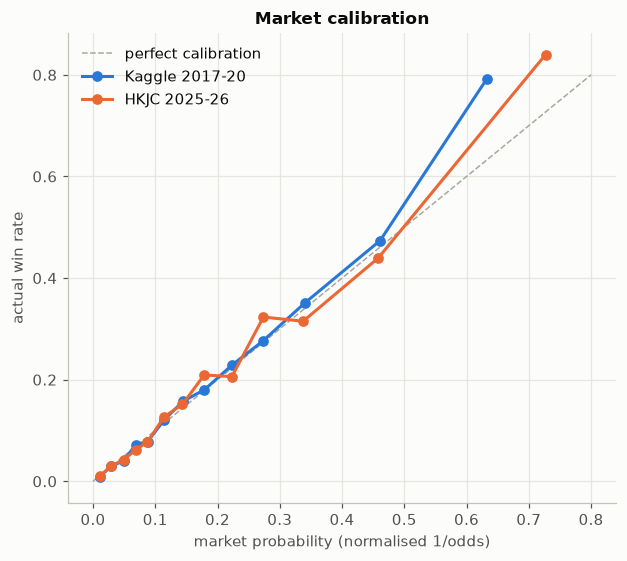

,source,races,market log loss,favourite win %,uniform log loss (1/field)
0,Kaggle 2017-20,2216,1.9873,31.3,2.4864
1,HKJC 2025-26,963,2.0351,29.2,2.5158


capped_runners  share
source season                        
hkjc   2025/26               0    0.0
       2026/27               0    0.0
kaggle 2017/18             689  0.087
       2018/19             522  0.054
       2019/20               0    0.0

In [6]:
bins = [0, .02, .04, .06, .08, .10, .13, .16, .20, .25, .30, .40, .55, 1]
fig, ax = plt.subplots(figsize=(5.8, 5.2))
ax.plot([0, .8], [0, .8], color="#a8a79f", linewidth=1, linestyle="--", label="perfect calibration")
rows = []
for src in ["kaggle", "hkjc"]:
    d = m[(m.source == src) & m.market_prob.notna()]
    g = d.groupby(pd.cut(d.market_prob, bins), observed=True).agg(pred=("market_prob", "mean"),
                                                                    won=("is_winner", "mean"),
                                                                    n=("is_winner", "size"))
    ax.plot(g.pred, g.won, marker="o", color=SRC[src][1], label=SRC[src][0])
    # per-race log loss of the market = mean over races of -log(p(winner))
    w = d[d.is_winner].groupby("race_id").market_prob.mean()
    fav = d.loc[d.groupby("race_id").market_prob.idxmax()]
    rows.append({"source": SRC[src][0], "races": d.race_id.nunique(),
                 "market log loss": round(float(-np.log(w).mean()), 4),
                 "favourite win %": round(100 * fav.is_winner.mean(), 1),
                 "uniform log loss (1/field)": round(float(np.log(d.groupby("race_id").size()).mean()), 4)})
ax.set_xlabel("market probability (normalised 1/odds)"); ax.set_ylabel("actual win rate")
ax.set_title("Market calibration"); ax.legend()
save(fig, "03_market_calibration")
display(pd.DataFrame(rows))
m.groupby(["source", "season"]).odds_capped.agg(capped_runners="sum", share="mean").round(3)

## 5. Draw bias - does the starting gate matter?

The orange/blue lines show the actual win rate by draw. The dashed grey line is **1 / field size**, the rate expected if the draw didn't matter. Happy Valley's tight turns usually favour low (inside) draws.

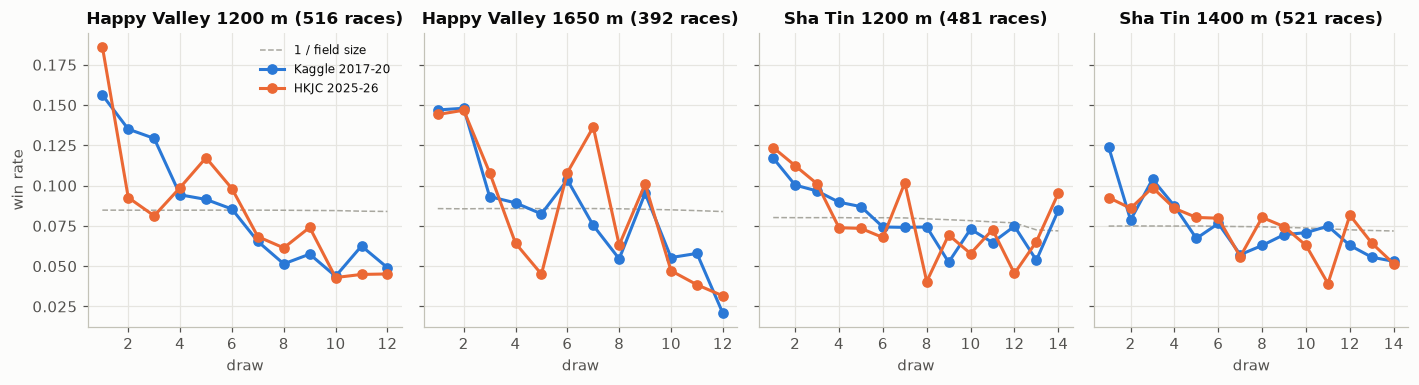

,course,source,races,draws 1-2 win %,draws 10+ win %,no-bias rate (1/field) %
0,Happy Valley 1200 m,Kaggle 2017-20,353,14.6,5.2,8.5
1,Happy Valley 1200 m,HKJC 2025-26,163,13.9,4.4,8.4
2,Happy Valley 1650 m,Kaggle 2017-20,281,14.7,4.5,8.6
3,Happy Valley 1650 m,HKJC 2025-26,111,14.5,3.9,8.6
4,Sha Tin 1200 m,Kaggle 2017-20,303,10.9,7.0,8.1
5,Sha Tin 1200 m,HKJC 2025-26,178,11.8,6.4,7.9
6,Sha Tin 1400 m,Kaggle 2017-20,358,10.1,6.4,7.5
7,Sha Tin 1400 m,HKJC 2025-26,163,8.9,6.0,7.4


In [7]:
groups = [("Happy Valley", "Turf", 1200), ("Happy Valley", "Turf", 1650),
          ("Sha Tin", "Turf", 1200), ("Sha Tin", "Turf", 1400)]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), sharey=True)
for ax, (trk, surf, dist) in zip(axes, groups):
    d = m[(m.track == trk) & (m.surface == surf) & (m.distance_m == dist) & m.draw.notna()]
    ax.plot(d.groupby("draw").size().index, (1 / d.groupby("draw").field_size.mean()).values,
            color="#a8a79f", linestyle="--", linewidth=1, label="1 / field size")
    for src in ["kaggle", "hkjc"]:
        x = d[d.source == src].groupby("draw").is_winner.mean()
        ax.plot(x.index, x.values, marker="o", color=SRC[src][1], label=SRC[src][0])
    ax.set_title(f"{trk} {dist} m ({len(d.drop_duplicates('race_id'))} races)"); ax.set_xlabel("draw")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].set_ylabel("win rate"); axes[0].legend(fontsize=8)
save(fig, "04_draw_bias")
rows = []
for trk, surf, dist in groups:
    d = m[(m.track == trk) & (m.surface == surf) & (m.distance_m == dist) & m.draw.notna()]
    for src in ["kaggle", "hkjc"]:
        x = d[d.source == src]
        rows.append({"course": f"{trk} {dist} m", "source": SRC[src][0], "races": x.race_id.nunique(),
                     "draws 1-2 win %": round(100 * x[x.draw <= 2].is_winner.mean(), 1),
                     "draws 10+ win %": round(100 * x[x.draw >= 10].is_winner.mean(), 1),
                     "no-bias rate (1/field) %": round(100 * (1 / x.field_size.astype(float)).mean(), 1)})
pd.DataFrame(rows)


## 6. Weight and rating vs result

In handicaps, better horses carry more weight. A higher win rate at higher weight means the handicapper doesn't fully equalise. `official_rating` is HKJC-only, and is the rating the horse raced off (pre-race).

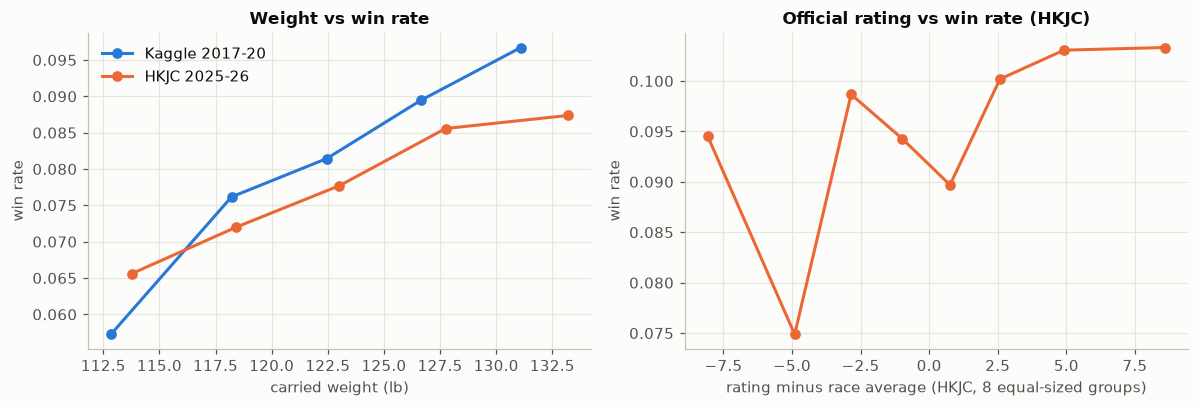

,source,weight band (lb),runners,win %
0,Kaggle 2017-20,"(100, 115]",3371,5.7
1,Kaggle 2017-20,"(115, 120]",5817,7.6
2,Kaggle 2017-20,"(120, 125]",5661,8.1
3,Kaggle 2017-20,"(125, 130]",6250,8.9
4,Kaggle 2017-20,"(130, 135]",5821,9.7
5,HKJC 2025-26,"(100, 115]",503,6.6
6,HKJC 2025-26,"(115, 120]",2333,7.2
7,HKJC 2025-26,"(120, 125]",3230,7.8
8,HKJC 2025-26,"(125, 130]",3354,8.6
9,HKJC 2025-26,"(130, 135]",2598,8.7


,rating vs race avg,win %
rbin,,
"(-19.89, -6.125]",-8.1,9.5
"(-6.125, -3.818]",-4.9,7.5
"(-3.818, -1.889]",-2.8,9.9
"(-1.889, -0.0769]",-1.0,9.4
"(-0.0769, 1.556]",0.8,9.0
"(1.556, 3.625]",2.6,10.0
"(3.625, 6.304]",4.9,10.3
"(6.304, 22.111]",8.6,10.3


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
wbins = [100, 115, 120, 125, 130, 135, 140]
wtab = []
for src in ["kaggle", "hkjc"]:
    d = m[m.source == src]
    g = d.groupby(pd.cut(d.carried_weight_lb, wbins), observed=True).agg(x=("carried_weight_lb", "mean"),
                                                                        win=("is_winner", "mean"),
                                                                        n=("is_winner", "size"))
    g = g[g.n >= 200]                                    # hide groups too small to trust
    axes[0].plot(g.x, g.win, marker="o", color=SRC[src][1], label=SRC[src][0])
    wtab.append(g.assign(source=SRC[src][0]))
axes[0].set_xlabel("carried weight (lb)"); axes[0].set_ylabel("win rate"); axes[0].set_title("Weight vs win rate")
axes[0].legend()
# rated HKJC runners only (blank ratings are not random - see section 2), compared with their race's rated field
h = m[(m.source == "hkjc") & m.official_rating.notna() & m.race_class.notna()].copy()
h["rating_vs_field"] = h.official_rating - h.groupby("race_id").official_rating.transform("mean")
h["rbin"] = pd.qcut(h.rating_vs_field, 8)            # 8 equal-sized groups of runners
g = h.groupby("rbin", observed=True).agg(x=("rating_vs_field", "mean"), win=("is_winner", "mean"))
axes[1].plot(g.x, g.win, marker="o", color=SRC["hkjc"][1])
axes[1].set_xlabel("rating minus race average (HKJC, 8 equal-sized groups)"); axes[1].set_ylabel("win rate")
axes[1].set_title("Official rating vs win rate (HKJC)")
save(fig, "05_weight_rating")
display(pd.concat(wtab).reset_index().rename(columns={"carried_weight_lb": "weight band (lb)"})
          .assign(win=lambda t: (100 * t.win).round(1))[["source", "weight band (lb)", "n", "win"]]
          .rename(columns={"n": "runners", "win": "win %"}))
g.assign(win=lambda t: (100 * t.win).round(1)).rename(columns={"x": "rating vs race avg", "win": "win %"}).round(1)


## 7. Sanity check - winning times

These should be similar across sources for the same distance and surface. Very different values would point to a parsing problem.

In [9]:
t = (m.drop_duplicates("race_id").groupby(["surface", "distance_m", "source"]).race_winner_time_s
       .median().unstack("source").round(2))
t.columns = [SRC[c][0] for c in t.columns]
t

HKJC 2025-26  Kaggle 2017-20
surface     distance_m                              
All Weather 1200               68.88           69.09
            1650               99.02           98.92
            1800               109.1          108.66
Turf        1000                56.7           56.96
            1200               69.34           69.74
            1400               81.59           82.03
            1600               94.37           94.66
            1650               99.75          100.26
            1800              108.28          108.62
            2000              121.46           121.8
            2200              136.53          137.15
            2400              148.05          146.28

## 8. People across the gap - do jockeys and trainers carry over?

History features (Week 3) can only link people who appear in both periods.

In [10]:
rows = []
for col in ["jockey_key", "trainer_key"]:
    k = set(m.loc[m.source == "kaggle", col].dropna()); h = set(m.loc[m.source == "hkjc", col].dropna())
    hk_rides = m[m.source == "hkjc"]
    share = hk_rides[col].isin(k).mean()
    rows.append({"who": col.split("_")[0], "kaggle": len(k), "hkjc": len(h), "in both": len(k & h),
                 "share of 2025-26 rides by someone also in 2017-20": f"{share:.0%}"})
pd.DataFrame(rows)

,who,kaggle,hkjc,in both,share of 2025-26 rides by someone also in 2017-20
0,jockey,89,47,27,68%
1,trainer,86,45,22,67%


In [11]:
top = (m[m.source == "hkjc"].groupby("jockey_key")
         .agg(rides=("is_winner", "size"), wins=("is_winner", "sum")).sort_values("rides", ascending=False).head(10))
top["win %"] = (100 * top.wins / top.rides).round(1)
top["rode in 2017-20"] = top.index.isin(set(m.loc[m.source == "kaggle", "jockey_key"]))
top

,rides,wins,win %,rode in 2017-20
jockey_key,,,,
Z PURTON,777,160,20.6,True
K TEETAN,723,57,7.9,True
A ATZENI,680,70,10.3,True
H BOWMAN,592,65,11.0,True
CL CHAU,591,54,9.1,True
A BADEL,554,41,7.4,True
MF POON,544,31,5.7,True
L HEWITSON,531,28,5.3,True
J ORMAN,523,37,7.1,False


## Next

- Write the findings at the top of this notebook, then save (Ctrl+S).
- Upload the figures and this notebook to S3 with the PowerShell commands in `docs/WEEK1-2_RUNBOOK.md`, step 5.4. Set `$B` and `$R` first.
- Week 3 builds the history features (form, jockey/trainer rates), using only races **before** each race.
